# Extensión: fNIRS con Cedalion: del registro crudo a la respuesta hemodinámica

**Especialización opcional (semana 17, opción “datos”).** Hasta ahora la ruta trabajó con
modelos y datos sintéticos. Aquí se analiza un **registro real** de espectroscopía funcional
en el infrarrojo cercano (fNIRS) con [Cedalion](https://github.com/ibs-lab/cedalion), siguiendo
los tutoriales 3 y 4 de Middell et al. (2026, *Neurophotonics* 13(S3), S32602).

**Pregunta:** efecto del movimiento de los dedos de una mano sobre la oxigenación de la corteza
motora del hemisferio **opuesto**.

| Paso | Semana de la ruta con la que conecta |
|---|---|
| Calidad de señal y artefactos | 16 (procesamiento de señales) |
| Ley de Beer-Lambert modificada | 2 (de una medida física a una variable del modelo) |
| Filtrado y espectro | 16 |
| GLM con respuesta hemodinámica | 12-13 (ajuste de modelos, GLM) |
| Contrastes y corrección por comparaciones múltiples | 11 (hipótesis previas) |

**Entorno:** este notebook necesita el entorno aislado de `extensions/fnirs-cedalion/`
(ver su README). La primera ejecución descarga el dataset de ejemplo (~67 MB) a la caché de Cedalion.

## 1. Qué mide fNIRS

Se emite luz infrarroja (760 y 850 nm) sobre el cuero cabelludo y se mide la que vuelve a unos
centímetros. Cada par fuente-detector es un **canal**. La hemoglobina oxigenada (HbO) y la
desoxigenada (HbR) absorben distinto en cada longitud de onda; si cambia su concentración, cambia
la intensidad detectada $I$. La **densidad óptica** es

$$\Delta OD_\lambda(t) = -\log\frac{I_\lambda(t)}{\bar I_\lambda}$$

y la **ley de Beer-Lambert modificada** la relaciona con los cambios de concentración:

$$\Delta OD_\lambda = \left(\varepsilon_{\lambda}^{HbO}\,\Delta[HbO] + \varepsilon_{\lambda}^{HbR}\,\Delta[HbR]\right) \cdot d \cdot DPF_\lambda$$

donde $\varepsilon$ son coeficientes de extinción, $d$ la distancia fuente-detector y $DPF$ el
factor de longitud de camino diferencial (la luz no viaja en línea recta). Con dos longitudes de
onda se resuelve un sistema 2×2 para $\Delta[HbO]$ y $\Delta[HbR]$.

fNIRS **no mide actividad neuronal directa**: mide la respuesta hemodinámica que la acompaña,
lenta (pico a los 5-8 s) y mezclada con fisiología sistémica (latido, respiración, ondas de Mayer).

In [1]:
import os
import warnings
from pathlib import Path

os.environ.setdefault("TQDM_DISABLE", "1")
warnings.filterwarnings("ignore", category=RuntimeWarning)
warnings.filterwarnings("ignore", message="The unit of the quantity is stripped")

import matplotlib.pyplot as plt
import numpy as np
import xarray as xr
from statsmodels.stats.multitest import multipletests

import cedalion
import cedalion.data
import cedalion.models.glm as glm
import cedalion.nirs
import cedalion.sigproc.frequency
import cedalion.sigproc.motion as motion
import cedalion.sigproc.quality as quality
from cedalion import units

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "pyproject.toml").exists())
OUT = ROOT / "extensions" / "fnirs-cedalion" / "outputs"
OUT.mkdir(parents=True, exist_ok=True)


def save(figure, name):
    if figure.get_layout_engine() is None:
        figure.tight_layout()
    figure.savefig(OUT / name, dpi=130)
    print(f"Saved: {(OUT / name).relative_to(ROOT).as_posix()}")


print("Cedalion", cedalion.__version__)
rec = cedalion.data.get_fingertappingDOT()
rec.stim.cd.rename_events({
    "1": "Control", "2": "FTapping/Left", "3": "FTapping/Right",
    "4": "BallSqueezing/Left", "5": "BallSqueezing/Right",
})
# The full recording lasts ~34 min; AR-IRLS on all of it takes more than 30 min. The first
# 1000 s keep 8 trials per hand (the Cedalion tutorial uses 310 s, with only 3 per hand).
WINDOW_END_S = 1000.0
rec.stim = rec.stim[rec.stim.onset <= WINDOW_END_S - 20]
amp = rec["amp"].sel(time=slice(0, WINDOW_END_S))
fs = 1 / float(amp.time.diff("time").mean())
print(f"{amp.sizes['channel']} canales x {amp.sizes['wavelength']} longitudes de onda, "
      f"{float(amp.time[-1]) / 60:.1f} min a {fs:.2f} Hz")
print(rec.stim.trial_type.value_counts().to_dict())

Cedalion

26.5.1

100 canales x 2 longitudes de onda, 16.7 min a 4.36 Hz

{'Control': 31, 'FTapping/Left': 8, 'FTapping/Right': 8, 'BallSqueezing/Left': 8, 'BallSqueezing/Right': 8}

### Montaje y señal cruda

Cada canal une una fuente (S) y un detector (D). Los **canales largos** (fuente y detector a
~3 cm) llegan a la corteza; los **cortos** (< 22.5 mm) solo atraviesan cuero cabelludo y sirven
para medir la fisiología superficial. Las posiciones 3D se proyectan a un plano visto desde arriba
usando los puntos preauriculares (LPA, RPA) y el eje nasion-inion.

La señal cruda es la intensidad de luz detectada en cada longitud de onda. A simple vista domina el
latido y la deriva lenta; la respuesta al *tapping* (marcas de color) no se distingue todavía.

Saved: extensions/fnirs-cedalion/outputs/montage_raw.png

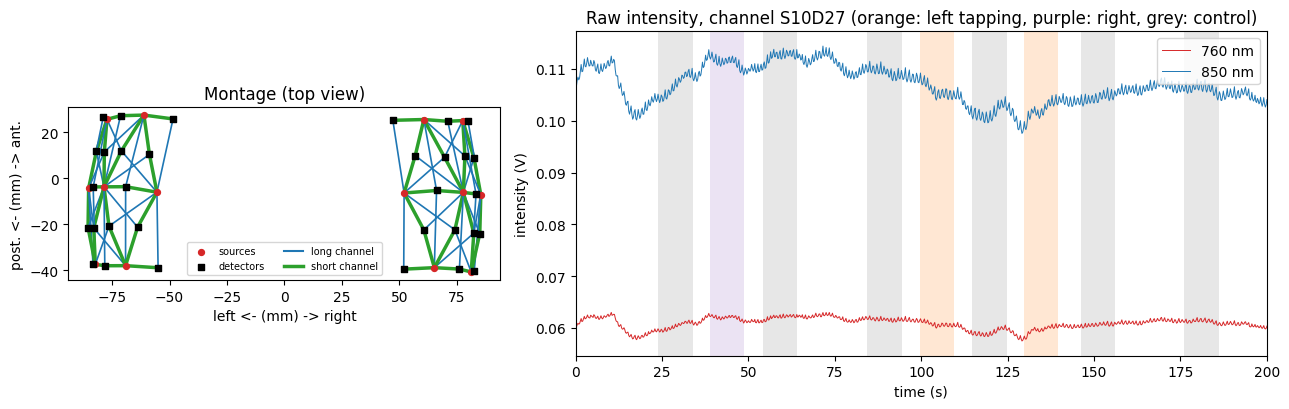

In [2]:
geometry = rec.geo3d.pint.dequantify()
lpa, rpa = geometry.sel(label="LPA").values, geometry.sel(label="RPA").values
nasion, inion = geometry.sel(label="Nz").values, geometry.sel(label="Iz").values
head_center = (lpa + rpa) / 2
left_right_axis = (rpa - lpa) / np.linalg.norm(rpa - lpa)
front_axis = nasion - inion
front_axis = front_axis - (front_axis @ left_right_axis) * left_right_axis
front_axis /= np.linalg.norm(front_axis)


def head_plane(points):
    """Project 3D points (mm) to (left-right, posterior-anterior) coordinates seen from above."""
    centered = np.asarray(points) - head_center
    return centered @ left_right_axis, centered @ front_axis


CONDITION_COLORS = {"FTapping/Left": "tab:orange", "FTapping/Right": "tab:purple", "Control": "tab:grey",
                    "BallSqueezing/Left": "tab:olive", "BallSqueezing/Right": "tab:cyan"}


def shade_stimuli(ax, t_start, t_end, conditions=("FTapping/Left", "FTapping/Right", "Control")):
    for _, row in rec.stim[rec.stim.trial_type.isin(conditions)].iterrows():
        if t_start <= row.onset <= t_end:
            ax.axvspan(row.onset, row.onset + row.duration, color=CONDITION_COLORS[row.trial_type], alpha=0.18, lw=0)


distances = cedalion.nirs.channel_distances(amp, rec.geo3d).pint.dequantify()
EXAMPLE_CHANNEL = "S10D27"
figure, axes = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={"width_ratios": [1, 1.6]})
for source, detector, distance in zip(amp.source.values, amp.detector.values, distances.values):
    xs, ys = head_plane([geometry.sel(label=source).values, geometry.sel(label=detector).values])
    axes[0].plot(xs, ys, color="tab:blue" if distance >= 22.5 else "tab:green", lw=1.2 if distance >= 22.5 else 2.5)
for kind, marker, color in (("S", "o", "tab:red"), ("D", "s", "k")):
    labels = [str(l) for l in geometry.label.values if str(l).startswith(kind) and str(l)[1:].isdigit()]
    xs, ys = head_plane(geometry.sel(label=labels).values)
    axes[0].scatter(xs, ys, marker=marker, s=18, color=color, zorder=3, label="sources" if kind == "S" else "detectors")
axes[0].plot([], [], color="tab:blue", label="long channel"); axes[0].plot([], [], color="tab:green", lw=2.5, label="short channel")
axes[0].set(aspect="equal", xlabel="left <- (mm) -> right", ylabel="post. <- (mm) -> ant.", title="Montage (top view)")
axes[0].legend(fontsize=7, loc="lower center", ncol=2)
for wavelength, color in zip(amp.wavelength.values, ("tab:red", "tab:blue")):
    trace = amp.sel(channel=EXAMPLE_CHANNEL, wavelength=wavelength).pint.dequantify()
    axes[1].plot(trace.time, trace, lw=0.7, color=color, label=f"{wavelength:.0f} nm")
shade_stimuli(axes[1], 0, 200)
axes[1].set(xlim=(0, 200), xlabel="time (s)", ylabel="intensity (V)",
            title=f"Raw intensity, channel {EXAMPLE_CHANNEL} (orange: left tapping, purple: right, grey: control)")
axes[1].legend(loc="upper right")
save(figure, "montage_raw.png")

## 2. Calidad de señal

Dos métricas por canal, en ventanas de 10 s:

- **Scalp coupling index (SCI):** correlación entre las dos longitudes de onda en la banda cardiaca.
  Si el optodo toca bien la piel, ambas ven el mismo pulso (SCI cercano a 1).
- **Peak spectral power (PSP):** potencia del pico cardiaco. Si es muy baja, no llega señal fisiológica.

Un canal se descarta si está “limpio” (SCI > 0.75 y PSP > 0.03) menos del 95 % del tiempo.

Saved: extensions/fnirs-cedalion/outputs/quality.png

Canales descartados:

['S13D26', 'S14D28']

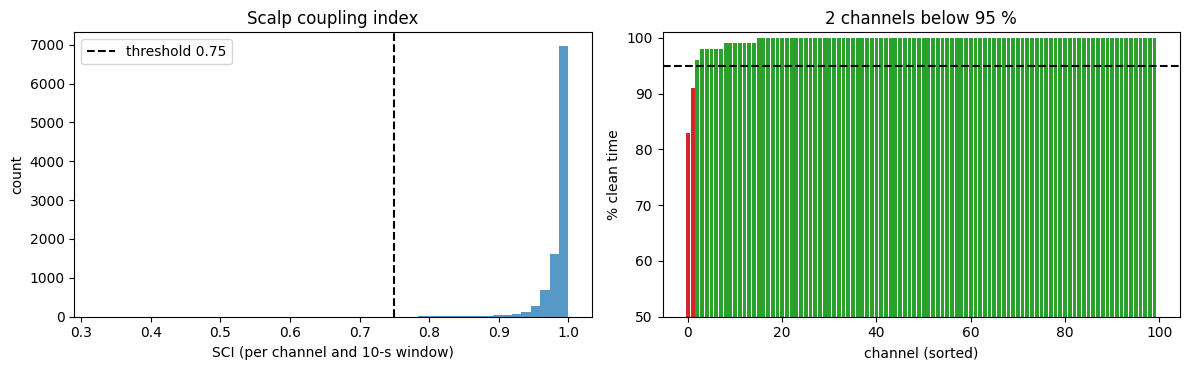

In [3]:
window = 10 * units.s
sci, sci_mask = quality.sci(amp, window, 0.75)
psp, psp_mask = quality.psp(amp, window, 0.03)
clean_mask = sci_mask & psp_mask
clean_fraction = clean_mask.sum("time") / clean_mask.sizes["time"]
bad_channels = list(clean_fraction.channel.values[(clean_fraction < 0.95).values])

figure, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].hist(sci.values.ravel(), bins=50, color="tab:blue", alpha=0.75)
axes[0].axvline(0.75, color="k", linestyle="--", label="threshold 0.75")
axes[0].set(xlabel="SCI (per channel and 10-s window)", ylabel="count", title="Scalp coupling index")
axes[0].legend()
order = np.argsort(clean_fraction.values)
axes[1].bar(np.arange(order.size), clean_fraction.values[order] * 100,
            color=["tab:red" if v < 0.95 else "tab:green" for v in clean_fraction.values[order]])
axes[1].axhline(95, color="k", linestyle="--")
axes[1].set(xlabel="channel (sorted)", ylabel="% clean time", ylim=(50, 101), title=f"{len(bad_channels)} channels below 95 %")
save(figure, "quality.png")
print("Canales descartados:", bad_channels)

## 3. Artefactos de movimiento

Los movimientos de cabeza desplazan los optodos y producen saltos y picos. Se corrigen en densidad
óptica con dos métodos encadenados:

- **TDDR** (*temporal derivative distribution repair*): repondera la derivada temporal para
  reducir los cambios bruscos que son atípicos respecto a su distribución.
- **Wavelet:** elimina coeficientes atípicos de la descomposición wavelet (picos cortos).

**Validación:** la *global variance of the temporal derivative* (GVTD), que crece con los
artefactos, debe bajar tras la corrección.

Saved: extensions/fnirs-cedalion/outputs/motion_gvtd.png

GVTD percentil 95: 0.0062 -> 0.0030 (52% menos)

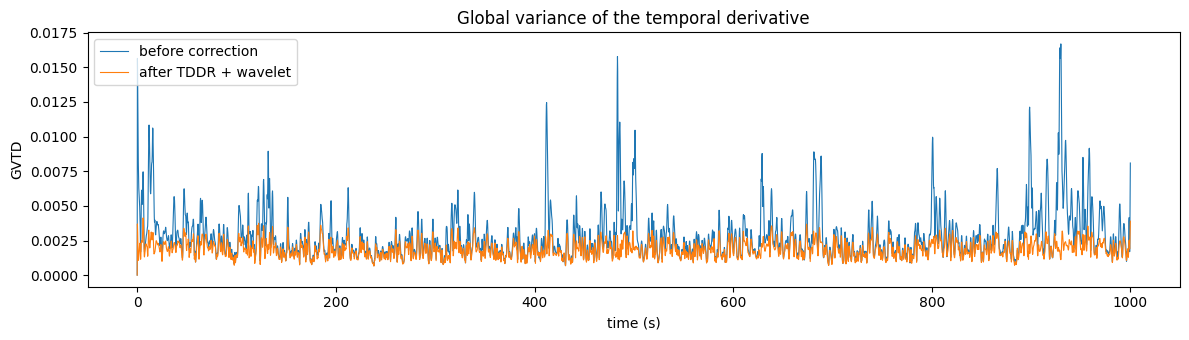

In [4]:
od = cedalion.nirs.cw.int2od(amp)
od_corrected = motion.wavelet(motion.tddr(od))
gvtd_before, _ = quality.gvtd(amp)
gvtd_after, _ = quality.gvtd(cedalion.nirs.cw.od2int(od_corrected, amp.mean("time")))

figure, ax = plt.subplots(figsize=(12, 3.5))
ax.plot(gvtd_before.time, gvtd_before, lw=0.8, label="before correction")
ax.plot(gvtd_after.time, gvtd_after, lw=0.8, label="after TDDR + wavelet")
ax.set(xlabel="time (s)", ylabel="GVTD", title="Global variance of the temporal derivative")
ax.legend()
save(figure, "motion_gvtd.png")

p95_before, p95_after = float(gvtd_before.quantile(0.95)), float(gvtd_after.quantile(0.95))
assert p95_after < p95_before, "motion correction should reduce GVTD"
print(f"GVTD percentil 95: {p95_before:.4f} -> {p95_after:.4f} ({1 - p95_after / p95_before:.0%} menos)")

Detalle del artefacto más fuerte (máximo de GVTD), en el canal donde la densidad óptica cambia más
bruscamente en ese momento:

Saved: extensions/fnirs-cedalion/outputs/motion_closeup.png

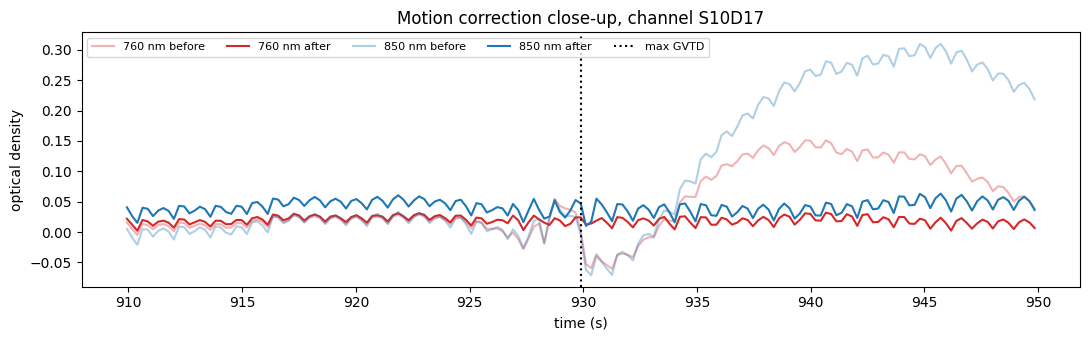

In [5]:
t_worst = float(gvtd_before.time[int(gvtd_before.argmax())])
segment = slice(max(0.0, t_worst - 20), t_worst + 20)
jump = np.abs(od.sel(time=segment).pint.dequantify().diff("time")).max(["time", "wavelength"])
worst_channel = str(jump.channel.values[int(jump.argmax())])
figure, ax = plt.subplots(figsize=(11, 3.5))
for wavelength, color in zip(od.wavelength.values, ("tab:red", "tab:blue")):
    before = od.sel(channel=worst_channel, wavelength=wavelength, time=segment).pint.dequantify()
    after = od_corrected.sel(channel=worst_channel, wavelength=wavelength, time=segment).pint.dequantify()
    ax.plot(before.time, before, color=color, alpha=0.35, lw=1.5, label=f"{wavelength:.0f} nm before")
    ax.plot(after.time, after, color=color, lw=1.5, label=f"{wavelength:.0f} nm after")
ax.axvline(t_worst, color="k", linestyle=":", label="max GVTD")
ax.set(xlabel="time (s)", ylabel="optical density", title=f"Motion correction close-up, channel {worst_channel}")
ax.legend(ncol=5, fontsize=8, loc="upper left")
save(figure, "motion_closeup.png")

## 4. De densidad óptica a hemoglobina, y su espectro

Se aplica Beer-Lambert modificada con $DPF = 6$ y el espectro de extinción de Prahl. El espectro
de potencia muestra lo que el GLM tendrá que separar de la respuesta al estímulo:

- **~1 Hz:** latido cardiaco.
- **~0.1 Hz:** ondas de Mayer (oscilaciones de presión arterial), justo en la banda de la respuesta hemodinámica.

Un filtro pasa-bajos a 0.5 Hz elimina el latido; las ondas de Mayer no se pueden filtrar sin
perder la señal, por eso se modelan con **canales cortos** (sección 5).

Saved: extensions/fnirs-cedalion/outputs/spectrum.png

Pico cardiaco en 1.03 Hz (62 latidos/min); unidades: micromolar

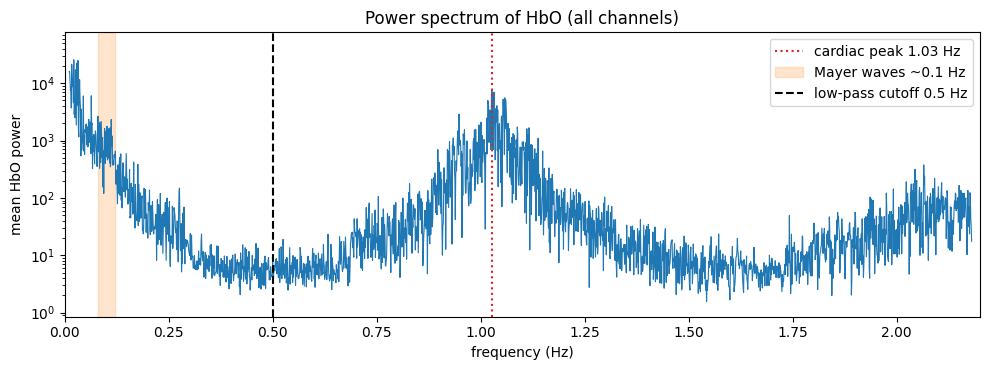

In [6]:
od_clean = od_corrected.sel(channel=~od_corrected.channel.isin(bad_channels))
dpf = xr.DataArray([6, 6], dims="wavelength", coords={"wavelength": amp.wavelength})
conc = cedalion.nirs.cw.od2conc(od_clean, rec.geo3d, dpf, spectrum="prahl")
conc_filtered = cedalion.sigproc.frequency.freq_filter(conc, 0 * units.Hz, 0.5 * units.Hz)

hbo = conc.sel(chromo="HbO").pint.dequantify().values
frequencies = np.fft.rfftfreq(hbo.shape[-1], d=1 / fs)
power = (np.abs(np.fft.rfft(hbo - hbo.mean(-1, keepdims=True), axis=-1)) ** 2).mean(0)
band = lambda lo, hi: (frequencies >= lo) & (frequencies <= hi)
cardiac_peak = frequencies[band(0.7, 2.0)][np.argmax(power[band(0.7, 2.0)])]

figure, ax = plt.subplots(figsize=(10, 3.8))
visible = band(0.01, 2.2)  # skip the 0 Hz bin, which is ~0 after removing the mean
ax.semilogy(frequencies[visible], power[visible], lw=0.8)
ax.set_ylim(np.percentile(power[visible], 1) / 3, power[visible].max() * 3)
ax.axvline(cardiac_peak, color="tab:red", linestyle=":", label=f"cardiac peak {cardiac_peak:.2f} Hz")
ax.axvspan(0.08, 0.12, color="tab:orange", alpha=0.2, label="Mayer waves ~0.1 Hz")
ax.axvline(0.5, color="k", linestyle="--", label="low-pass cutoff 0.5 Hz")
ax.set(xlim=(0, 2.2), xlabel="frequency (Hz)", ylabel="mean HbO power", title="Power spectrum of HbO (all channels)")
ax.legend()
save(figure, "spectrum.png")

assert 0.8 < cardiac_peak < 1.8, cardiac_peak
print(f"Pico cardiaco en {cardiac_peak:.2f} Hz ({cardiac_peak * 60:.0f} latidos/min); unidades: {conc.pint.units}")

Así queda un canal después de convertir a hemoglobina y filtrar: es la serie que recibe el GLM.
HbO y HbR suelen moverse en sentidos opuestos; el latido ya no está, pero las oscilaciones lentas sí.

Saved: extensions/fnirs-cedalion/outputs/hemoglobin_trace.png

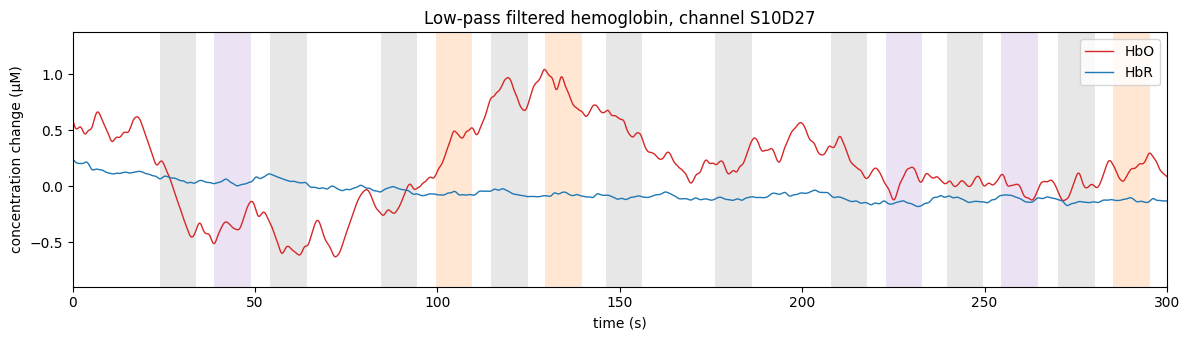

In [7]:
figure, ax = plt.subplots(figsize=(12, 3.5))
for chromo, color in (("HbO", "tab:red"), ("HbR", "tab:blue")):
    trace = conc_filtered.sel(channel=EXAMPLE_CHANNEL, chromo=chromo).pint.dequantify()
    ax.plot(trace.time, trace, color=color, lw=1, label=chromo)
shade_stimuli(ax, 0, 300)
ax.set(xlim=(0, 300), xlabel="time (s)", ylabel="concentration change (µM)",
       title=f"Low-pass filtered hemoglobin, channel {EXAMPLE_CHANNEL}")
ax.legend(loc="upper right")
save(figure, "hemoglobin_trace.png")

## 5. GLM: separar la respuesta al estímulo de todo lo demás

Para cada canal $c$ y cromóforo, el GLM explica la serie como suma de regresores:

$$y_c(t) = \underbrace{\sum_{k,j} \beta^{HRF}_{k,j}\, (g_j * s_k)(t)}_{\text{respuesta a cada condición } k}
 + \underbrace{\sum_m \beta^{drift}_m \cos(\pi m t / T)}_{\text{deriva lenta}}
 + \underbrace{\beta^{short}\, \bar y_{short}(t)}_{\text{fisiología superficial}} + \varepsilon_c(t)$$

- $s_k$ es el tren de estímulos de la condición $k$ y $g_j$ son **núcleos gaussianos** espaciados
  1.5 s (de −2 a 15 s): la forma de la respuesta no se impone, se estima.
- Los **canales cortos** (< 22.5 mm) solo ven cuero cabelludo; su promedio captura la fisiología
  sistémica (incluidas las ondas de Mayer) que contamina los canales largos.
- El ruido fNIRS está autocorrelacionado, lo que infla los $t$ de mínimos cuadrados ordinarios.
  **AR-IRLS** ajusta un modelo autorregresivo al residuo, preblanquea y repondera de forma robusta.

Se usan los primeros 1000 s del registro (8 ensayos por mano). El ajuste tarda unos minutos.

In [8]:
long_channels, short_channels = cedalion.nirs.split_long_short_channels(
    conc_filtered, rec.geo3d, distance_threshold=22.5 * units.mm
)
kernels = glm.basis_functions.GaussianKernels(
    t_pre=2 * units.s, t_post=15 * units.s, t_delta=1.5 * units.s, t_std=2 * units.s
)
design = (
    glm.design_matrix.hrf_regressors(long_channels, rec.stim, kernels)
    & glm.design_matrix.drift_cosine_regressors(conc_filtered, fmax=0.02 * units.Hz)
    & glm.design_matrix.average_short_channel_regressor(short_channels)
)
results = glm.fit(long_channels, design, noise_model="ar_irls", max_jobs=-1)
print(f"{long_channels.sizes['channel']} canales largos, {short_channels.sizes['channel']} cortos; "
      f"{design.common.sizes['regressor']} regresores comunes")

44 canales largos, 54 cortos; 96 regresores comunes

La **matriz de diseño** muestra cada regresor (filas) a lo largo del tiempo: bloques de núcleos
gaussianos desplazados tras cada estímulo, los cosenos lentos de la deriva y, abajo, el promedio de
los canales cortos.

Saved: extensions/fnirs-cedalion/outputs/design_matrix.png

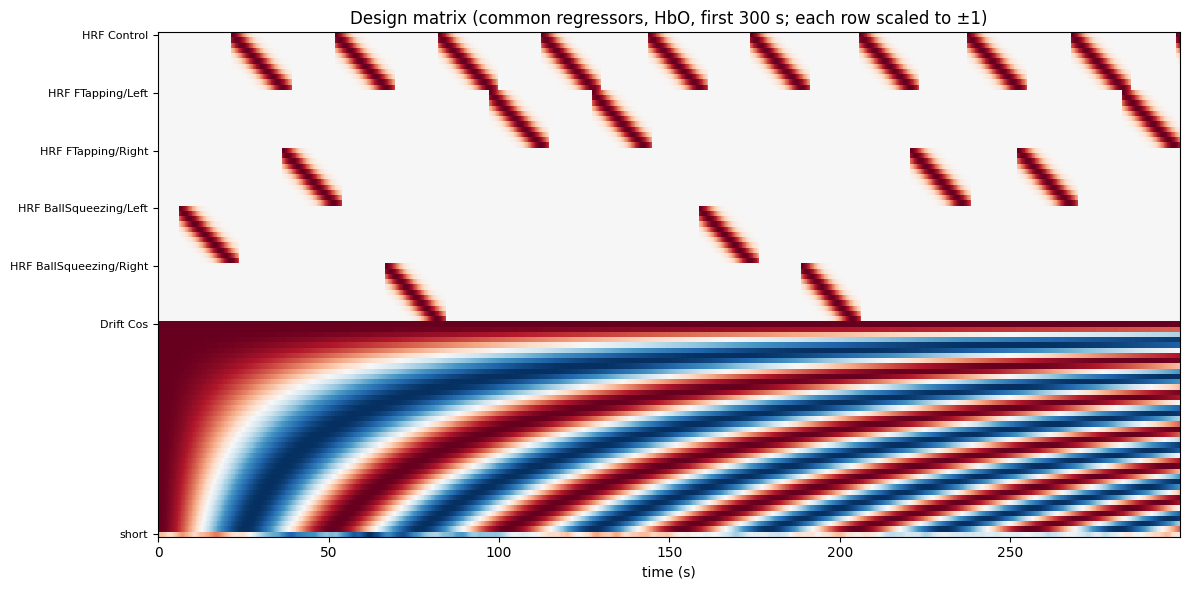

In [9]:
matrix = design.common.sel(chromo="HbO", time=design.common.time <= 300).transpose("regressor", "time")
values = matrix.pint.dequantify().values if hasattr(matrix, "pint") else matrix.values
values = values / np.maximum(np.abs(values).max(axis=1, keepdims=True), 1e-12)
figure, ax = plt.subplots(figsize=(12, 6))
ax.imshow(values, aspect="auto", cmap="RdBu_r", vmin=-1, vmax=1, interpolation="nearest",
          extent=(float(matrix.time[0]), float(matrix.time[-1]), matrix.sizes["regressor"] - 0.5, -0.5))
names = [str(n) for n in matrix.regressor.values]
first_of_group = [i for i, n in enumerate(names) if i == 0 or n.rsplit(" ", 1)[0] != names[i - 1].rsplit(" ", 1)[0]]
ax.set_yticks(first_of_group, [names[i].rsplit(" ", 1)[0] for i in first_of_group], fontsize=8)
ax.set(xlabel="time (s)", title="Design matrix (common regressors, HbO, first 300 s; each row scaled to ±1)")
save(figure, "design_matrix.png")

## 6. Hipótesis y contraste

**Hipótesis:** la HbO media entre 5 y 10 s tras el inicio del *tapping* aumenta respecto a la
línea base (**activación**), y esa activación predomina en el hemisferio **contralateral** a la mano.

El contraste integra cada regresor gaussiano en esa ventana (como en el tutorial 4 de Cedalion) y
se prueba con un test $t$ por canal. Con 40+ canales, se corrige por comparaciones múltiples con
**Benjamini-Hochberg** (tasa de falsos descubrimientos del 5 %).

**Referencia del contraste.** El tutorial de Cedalion contrasta *tapping* − “Control”. Aquí se
compara con la **línea base** implícita del GLM (los periodos sin estímulo), y se prueba también la
condición Control sola: si Control no es un reposo neutro, restarla mezclaría dos efectos. Elegir
el contraste es parte de la hipótesis y debe justificarse antes de ver los resultados.

El test es bilateral: un canal puede ser significativo porque la HbO **sube** (activación) o
porque **baja** (desactivación). Solo los primeros cuentan para la hipótesis; los segundos se
reportan aparte.

El hemisferio de cada canal se obtiene proyectando su punto medio sobre el eje que une los puntos
preauriculares izquierdo (LPA) y derecho (RPA). La lateralización se resume con el índice

$$LI = \frac{n_\text{contra} - n_\text{ipsi}}{n_\text{contra} + n_\text{ipsi}} \in [-1, 1]$$

donde $n$ es el número de canales con activación significativa en cada hemisferio
($LI = 1$: todo contralateral; $0$: bilateral; $-1$: todo ipsilateral).

In [10]:
def window_contrast(condition, t_start=5.0, t_end=10.0):
    """Weights that integrate the condition's HRF regressors over [onset + t_start, onset + t_end]."""
    time = design.common.time.values
    mask = np.zeros(time.size)
    for _, row in rec.stim[rec.stim.trial_type == condition].iterrows():
        mask[(time >= row.onset + t_start) & (time <= row.onset + t_end)] = 1.0
    weights = np.zeros(design.common.sizes["regressor"])
    for i, name in enumerate(design.common.regressor.values):
        if name.startswith(f"HRF {condition} "):
            weights[i] = np.trapezoid(design.common[:, i, 0] * mask, time)
    return weights


hypotheses = {"Left": window_contrast("FTapping/Left"),
              "Right": window_contrast("FTapping/Right"),
              "Control": window_contrast("Control")}
tests = results.sm.t_test(list(hypotheses.values()))

midpoints = np.array([(geometry.sel(label=s).values + geometry.sel(label=d).values) / 2
                      for s, d in zip(long_channels.source.values, long_channels.detector.values)])
side = (midpoints - head_center) @ left_right_axis  # > 0: right hemisphere
contralateral_sign = {"Left": 1, "Right": -1, "Control": 0}

summary = {}
for h, hand in enumerate(hypotheses):
    per_channel = tests.sel(chromo="HbO")
    assert list(per_channel.channel.values) == list(long_channels.channel.values)
    p_values = tests.sm.p_values().sel(chromo="HbO", hypothesis=h).values
    significant, q_values, _, _ = multipletests(p_values, alpha=0.05, method="fdr_bh")
    effects = np.array([np.atleast_1d(result.effect)[h] for result in per_channel.values])
    activated, deactivated = significant & (effects > 0), significant & (effects < 0)
    contra = int(np.sum(activated & (np.sign(side) == contralateral_sign[hand])))
    ipsi = int(activated.sum()) - contra
    li = (contra - ipsi) / (contra + ipsi) if activated.any() else np.nan
    deactivated_ipsi = int(np.sum(deactivated & (np.sign(side) == -contralateral_sign[hand])))
    summary[hand] = dict(effects=effects, p=p_values, q=q_values, activated=activated,
                         deactivated=deactivated, contra=contra, ipsi=ipsi, li=li)
    if hand == "Control":
        print(f"Control       : {activated.sum():2d} canales con aumento de HbO, "
              f"{deactivated.sum()} con disminución (mediana del efecto {np.median(effects):+.2f})")
    else:
        li_text = f"LI = {li:+.2f}" if activated.any() else "LI no definido"
        print(f"Mano {hand.lower():9s}: {activated.sum():2d} canales con activación "
              f"({contra} contralaterales, {ipsi} ipsilaterales; {li_text}); "
              f"{deactivated.sum()} con desactivación ({deactivated_ipsi} ipsilaterales)")
hands = ("Left", "Right")

Mano left     : 12 canales con activación (11 contralaterales, 1 ipsilaterales; LI = +0.83); 9 con desactivación (9 ipsilaterales)

Mano right    :  0 canales con activación (0 contralaterales, 0 ipsilaterales; LI no definido); 7 con desactivación (0 ipsilaterales)

Control       :  2 canales con aumento de HbO, 10 con disminución (mediana del efecto -1.96)

## 7. Mapa de activación

Cada punto es un canal largo en el plano de la cabeza (vista superior). Color: efecto en HbO
(ventana 5-10 s). Borde negro: activación significativa; borde gris discontinuo: desactivación
significativa.

Saved: extensions/fnirs-cedalion/outputs/activation_map.png

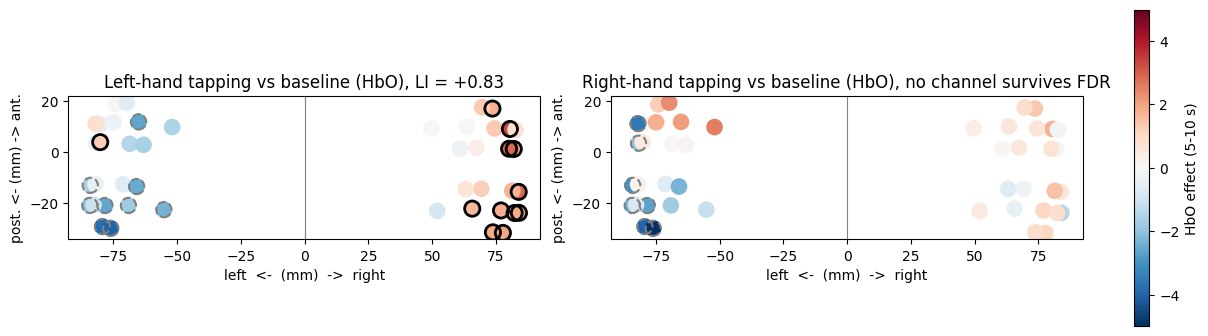

In [11]:
x_plane, y_plane = head_plane(midpoints)

figure, axes = plt.subplots(1, 2, figsize=(12, 3.6), layout="constrained")
limit = max(np.abs(summary[hand]["effects"]).max() for hand in hands)
for ax, hand in zip(axes, hands):
    entry = summary[hand]
    scatter = ax.scatter(x_plane, y_plane, c=entry["effects"], cmap="RdBu_r", vmin=-limit, vmax=limit, s=120)
    ax.scatter(x_plane[entry["activated"]], y_plane[entry["activated"]], s=120, facecolors="none",
               edgecolors="k", linewidths=2)
    ax.scatter(x_plane[entry["deactivated"]], y_plane[entry["deactivated"]], s=120, facecolors="none",
               edgecolors="grey", linewidths=1.5, linestyle="--")
    ax.axvline(0, color="grey", lw=0.8)
    li_label = f"LI = {entry['li']:+.2f}" if entry["activated"].any() else "no channel survives FDR"
    ax.set(title=f"{hand}-hand tapping vs baseline (HbO), {li_label}",
           xlabel="left  <-  (mm)  ->  right", ylabel="post. <- (mm) -> ant.", aspect="equal")
figure.colorbar(scatter, ax=axes, shrink=0.9, label="HbO effect (5-10 s)")
save(figure, "activation_map.png")

## 8. Respuesta hemodinámica estimada

Con los coeficientes de los núcleos gaussianos se reconstruye la forma de la respuesta (± 1 error
estándar) en el canal activado **más significativo** (menor valor q) de cada mano; la regla se fija
antes de mirar las curvas para no elegir la más bonita. Si ningún canal sobrevive a la corrección,
se muestra el de menor *p* sin corregir y se indica en el título. La firma clásica de una activación es que
HbO sube con pico a los 5-8 s y HbR baja algo menos.

Saved: extensions/fnirs-cedalion/outputs/hrf.png

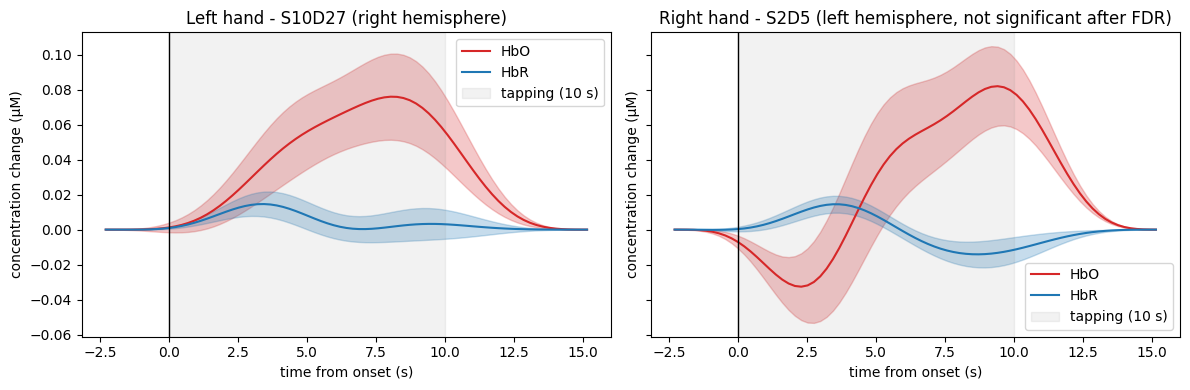

In [12]:
extract = glm.design_matrix.hrf_extract_regressors(long_channels, rec.stim, kernels)
figure, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
peaks = {}
for ax, hand in zip(axes, hands):
    entry = summary[hand]
    significant_after_fdr = bool(entry["activated"].any())
    # Most significant activated channel; if none survives FDR, the positive effect with the
    # smallest uncorrected p-value, clearly labelled as not significant.
    candidates = np.flatnonzero(entry["activated"] if significant_after_fdr else entry["effects"] > 0)
    best = int(candidates[np.argmin(entry["p"][candidates])])
    channel = long_channels.channel.values[best]
    mean, std = glm.predict_with_uncertainty(
        long_channels, results, extract, results.sm.params.regressor.str.startswith(f"HRF FTapping/{hand}")
    )
    for chromo, color in (("HbO", "tab:red"), ("HbR", "tab:blue")):
        m, s = mean.sel(channel=channel, chromo=chromo), std.sel(channel=channel, chromo=chromo)
        ax.plot(m.time, m, color=color, label=chromo)
        ax.fill_between(m.time, m - s, m + s, color=color, alpha=0.25)
    hbo_curve = mean.sel(channel=channel, chromo="HbO")
    hbr_curve = mean.sel(channel=channel, chromo="HbR")
    in_window = (hbo_curve.time >= 5) & (hbo_curve.time <= 10)
    peaks[hand] = dict(channel=channel, hemisphere="right" if side[best] > 0 else "left",
                       significant=significant_after_fdr, q=float(entry["q"][best]),
                       t_peak=float(hbo_curve.time[int(hbo_curve.argmax())]), hbo_peak=float(hbo_curve.max()),
                       hbo_min=float(hbo_curve.min()), hbr_window=float(hbr_curve[in_window].mean()),
                       curves={c: (mean.time.values, mean.sel(channel=channel, chromo=c).values,
                                   std.sel(channel=channel, chromo=c).values) for c in ("HbO", "HbR")})
    ax.axvline(0, color="k", lw=1)
    ax.axvspan(0, 10, color="grey", alpha=0.1, label="tapping (10 s)")
    label = "" if significant_after_fdr else ", not significant after FDR"
    ax.set(title=f"{hand} hand - {channel} ({peaks[hand]['hemisphere']} hemisphere{label})",
           xlabel="time from onset (s)", ylabel="concentration change (µM)")
    ax.legend()
save(figure, "hrf.png")

### El modelo sobre los datos

En el canal más significativo de la mano izquierda: la serie medida, el modelo completo y solo la
parte de “fondo” (deriva + canales cortos). Lo que el fondo no explica y coincide con los bloques de
*tapping* es lo que el GLM atribuye a la respuesta.

Fíjate en que el fondo (verde) ya sigue casi toda la señal: un $R^2$ alto no significa que la
respuesta al estímulo sea grande, sino que la deriva y la fisiología dominan la varianza.

Saved: extensions/fnirs-cedalion/outputs/model_fit.png

R^2 del modelo en S10D27 (HbO): 0.97

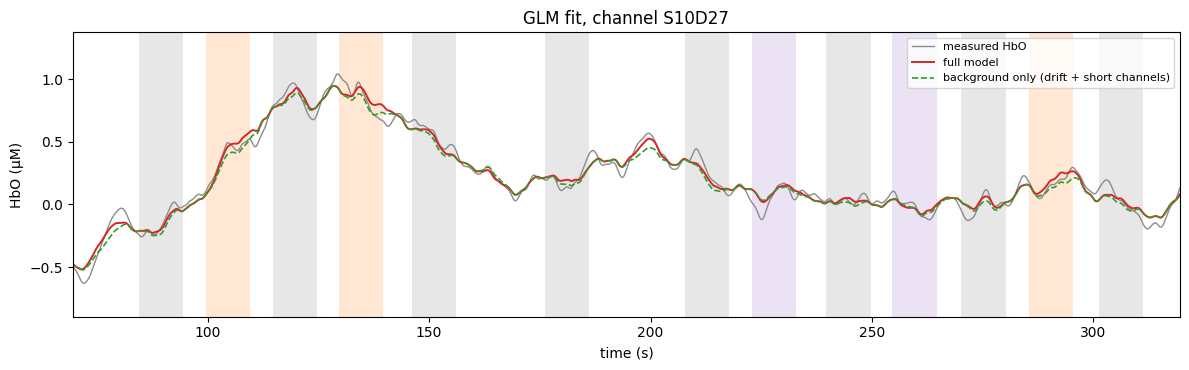

In [13]:
best_left = peaks["Left"]["channel"]
predicted = glm.predict(long_channels, results.sm.params, design)
background_params = results.sm.params.sel(
    regressor=results.sm.params.regressor.str.startswith("Drift") | results.sm.params.regressor.str.startswith("short")
)
background = glm.predict(long_channels, background_params, design)
left_onsets = rec.stim[rec.stim.trial_type == "FTapping/Left"].onset.values
t0 = max(0.0, float(left_onsets[0]) - 30)
figure, ax = plt.subplots(figsize=(12, 3.8))
measured = long_channels.sel(channel=best_left, chromo="HbO").pint.dequantify()
ax.plot(measured.time, measured, color="0.55", lw=1, label="measured HbO")
ax.plot(predicted.time, predicted.sel(channel=best_left, chromo="HbO"), color="tab:red", lw=1.4, label="full model")
ax.plot(background.time, background.sel(channel=best_left, chromo="HbO"), color="tab:green", lw=1.2,
        linestyle="--", label="background only (drift + short channels)")
shade_stimuli(ax, t0, t0 + 250)
ax.set(xlim=(t0, t0 + 250), xlabel="time (s)", ylabel="HbO (µM)", title=f"GLM fit, channel {best_left}")
ax.legend(loc="upper right", fontsize=8)
save(figure, "model_fit.png")

residual = measured.values - predicted.sel(channel=best_left, chromo="HbO").values
r_squared = 1 - np.nanvar(residual) / np.nanvar(measured.values)
print(f"R^2 del modelo en {best_left} (HbO): {r_squared:.2f}")

### Validación cruzada con un método sin modelo

El **promedio por bloques** (*block average*) es el método más simple: cortar la señal alrededor de
cada inicio de *tapping*, restar la media de los 2 s previos y promediar los 8 ensayos. No separa la
fisiología ni los solapamientos entre ensayos, pero tampoco supone nada sobre la forma de la respuesta.
Si el GLM está bien especificado, ambas estimaciones deberían parecerse.

Saved: extensions/fnirs-cedalion/outputs/block_average_vs_glm.png

Correlación promedio por bloques vs GLM:

{'HbO': 0.88, 'HbR': 0.83}

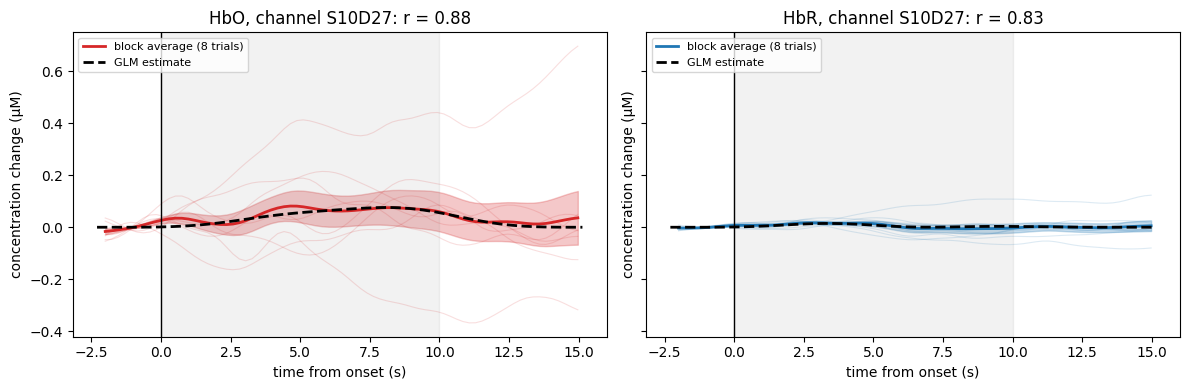

In [14]:
signal = long_channels.sel(channel=best_left).pint.dequantify()
relative_time = np.arange(-2.0, 15.0 + 1e-9, 1 / fs)
epochs = {c: [] for c in ("HbO", "HbR")}
for onset in left_onsets:
    for c in epochs:
        trace = signal.sel(chromo=c)
        values = np.interp(onset + relative_time, trace.time.values, trace.values)
        epochs[c].append(values - values[relative_time < 0].mean())
figure, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
block_correlation = {}
for ax, c, color in zip(axes, ("HbO", "HbR"), ("tab:red", "tab:blue")):
    trials = np.array(epochs[c])
    block_mean, block_sem = trials.mean(0), trials.std(0, ddof=1) / np.sqrt(len(trials))
    for trial in trials:
        ax.plot(relative_time, trial, color=color, alpha=0.15, lw=0.8)
    ax.plot(relative_time, block_mean, color=color, lw=2, label=f"block average ({len(trials)} trials)")
    ax.fill_between(relative_time, block_mean - block_sem, block_mean + block_sem, color=color, alpha=0.25)
    glm_time, glm_mean, glm_std = peaks["Left"]["curves"][c]
    ax.plot(glm_time, glm_mean, color="k", lw=2, linestyle="--", label="GLM estimate")
    block_correlation[c] = float(np.corrcoef(np.interp(glm_time, relative_time, block_mean), glm_mean)[0, 1])
    ax.axvspan(0, 10, color="grey", alpha=0.1)
    ax.axvline(0, color="k", lw=1)
    ax.set(title=f"{c}, channel {best_left}: r = {block_correlation[c]:.2f}", xlabel="time from onset (s)",
           ylabel="concentration change (µM)")
    ax.legend(fontsize=8, loc="upper left")
save(figure, "block_average_vs_glm.png")
print("Correlación promedio por bloques vs GLM:", {c: round(v, 2) for c, v in block_correlation.items()})

## 9. Validación

Comprobaciones que deben cumplirse **sea cual sea el resultado**, para confiar en el análisis:

1. **Orientación de la cabeza:** C3 (corteza motora izquierda) cae a la izquierda del eje LPA→RPA
   y C4 a la derecha. Si fallara, toda la asignación de hemisferios estaría invertida.
2. **Latencia y signo de la respuesta:** en el canal significativo de cada mano, el pico de HbO es
   positivo, llega entre 3 y 12 s (la escala temporal de la respuesta hemodinámica) y domina sobre
   cualquier descenso inicial.

Se **reportan, no se exigen**: cuántos canales sobreviven a la corrección, la lateralización (LI)
y la HbR, que en datos reales no siempre baja de forma clara. Son resultados, y se discuten en la
sección 10.

In [15]:
c3 = float((geometry.sel(label="C3").values - head_center) @ left_right_axis)
c4 = float((geometry.sel(label="C4").values - head_center) @ left_right_axis)
assert c3 < 0 < c4, (c3, c4)
print(f"C3 a {c3:.0f} mm y C4 a {c4:+.0f} mm del centro: eje izquierda-derecha correcto")
for hand in hands:
    peak = peaks[hand]
    if peak["significant"]:
        assert 3 <= peak["t_peak"] <= 12 and peak["hbo_peak"] > abs(peak["hbo_min"]), peak
    status = "significativo" if peak["significant"] else "no significativo tras FDR"
    print(f"Mano {hand.lower()}: canal {peak['channel']} ({peak['hemisphere']}, q = {peak['q']:.2g}, {status}), "
          f"pico HbO {peak['hbo_peak']:.3f} µM a {peak['t_peak']:.1f} s; HbR media en 5-10 s {peak['hbr_window']:+.3f} µM")

C3 a -70 mm y C4 a +70 mm del centro: eje izquierda-derecha correcto

Mano left: canal S10D27 (right, q = 0.0056, significativo), pico HbO 0.076 µM a 8.0 s; HbR media en 5-10 s +0.003 µM

Mano right: canal S2D5 (left, q = 0.11, no significativo tras FDR), pico HbO 0.082 µM a 9.4 s; HbR media en 5-10 s -0.008 µM

## 10. Interpretación y límites

- **Mano izquierda: activación clara y contralateral.** 12 canales aumentan su HbO y 11 están en
  el hemisferio derecho (LI = +0.83). El canal más significativo (S10D27, q = 0.006) tiene la forma
  esperada: la HbO sube durante el *tapping* con pico a los ~8 s, y el promedio por bloques sin
  modelo reproduce esa forma (r = 0.88). La HbR apenas cambia y no baja con claridad.
- **Mano derecha: tendencia en la dirección esperada, pero no concluyente.** Ningún canal sobrevive
  a la corrección FDR. El de menor *p* (S2D5, q = 0.11) está en el hemisferio izquierdo
  (contralateral) y muestra la firma clásica (HbO sube con pico a los ~9 s y HbR baja), pero con
  8 ensayos la evidencia no alcanza. La hipótesis se cumple para la mano izquierda y queda abierta
  para la derecha.
- **El control no es un reposo neutro:** la HbO *disminuye* en 10 canales durante la condición
  Control. Restarlo, como hace el tutorial, convierte esas disminuciones en “activaciones” aparentes
  del *tapping*; con ese contraste, la mano derecha muestra un patrón bilateral engañoso. Elegir el
  contraste es parte de la hipótesis.
- **Desactivaciones:** aparecen en el hemisferio **izquierdo con ambas manos** (9 con la izquierda,
  7 con la derecha). Como no dependen de la mano, es más probable que reflejen algo común a la tarea
  o a esos canales (por ejemplo, fisiología sistémica que el canal corto no elimina del todo) que una
  inhibición motora específica. Con estos datos no se puede decidir.

- **Un solo sujeto, una sesión y 8 ensayos por mano:** no permite generalizar (haría falta un
  análisis de grupo, por ejemplo con `get_multisubject_fingertapping_path`), y con tan pocos
  ensayos el patrón puede cambiar al usar el registro completo.
- **Decisiones del análisis:** umbrales de calidad, métodos de corrección, DPF, filtro y ventana
  del contraste afectan el resultado. El estudio FRESH (citado en el artículo) mostró que equipos
  distintos llegan a conclusiones distintas con los mismos datos: documenta y justifica cada elección.
- **Siguiente paso:** el tutorial 5 de Cedalion reconstruye esta activación en el espacio de la
  corteza (DOT), y el 6 la decodifica ensayo a ensayo con validación cruzada (semana 14).

**Para tu entrega:** cambia la ventana del contraste a 10-15 s o quita el regresor de canales
cortos; predice el efecto sobre el LI antes de ejecutar y compara.

## Referencias de los métodos usados

- Middell, E. et al. (2026). Cedalion tutorial: a Python-based framework for comprehensive analysis
  of multimodal fNIRS and DOT. *Neurophotonics* 13(S3), S32602. doi:10.1117/1.NPh.13.S3.S32602
- Pollonini, L. et al. (2016). PHOEBE: a method for real time mapping of optodes-scalp coupling in
  functional near-infrared spectroscopy. *Biomedical Optics Express* 7(12). SCI y PSP.
- Fishburn, F. A. et al. (2019). Temporal Derivative Distribution Repair (TDDR). *NeuroImage* 184.
- Molavi, B. & Dumont, G. A. (2012). Wavelet-based motion artifact removal for fNIRS.
  *Physiological Measurement* 33(2).
- Sherafati, A. et al. (2020). Global motion detection and censoring in high-density diffuse optical
  tomography (GVTD). *Human Brain Mapping* 41(14).
- Barker, J. W., Aarabi, A. & Huppert, T. J. (2013). Autoregressive model based algorithm for
  correcting motion and serially correlated errors in fNIRS (AR-IRLS). *Biomedical Optics Express* 4(8).